In [1]:
%matplotlib inline
import warnings
import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac

warnings.filterwarnings("ignore", category=ac.ActiveSubspacesWarning)
SEED = 2683

# Antarctic sea-level contribution of a CISM basal-melt ensemble

**Paper:** Mira Berdahl$^{1,3}$, Gunter Leguy$^{2}$, William H. Lipscomb$^{2}$ and Nathan M. Urban$^{3,4}$,
"Statistical emulation of a perturbed basal melt ensemble of an ice sheet model to better quantify Antarctic
sea level rise uncertainties", *The Cryosphere* 15, 2683–2699 (2021),
[doi:10.5194/tc-15-2683-2021](https://doi.org/10.5194/tc-15-2683-2021).

$^1$ Department of Earth and Space Sciences, University of Washington, Seattle, WA, USA
$^2$ Climate and Global Dynamics Laboratory, National Center for Atmospheric Research, Boulder, CO, USA
$^3$ Computational Physics and Methods Group, Los Alamos National Laboratory, Los Alamos, NM, USA
$^4$ Computational Science Initiative, Brookhaven National Laboratory, Upton, NY, USA

Notebook: Claude (Anthropic) for P. Constantine, 2026

## Summary

Berdahl et al. ran the Community Ice Sheet Model (CISM v2.1) on the whole Antarctic ice sheet at 4 km for
200 years, 500 times, each run forced by its own sigmoid basal-melt anomaly in each of five ocean basins
(three parameters per basin, 15 inputs). This notebook uses the 491 runs that reached year 200, as stored by
the authors, and estimates an active subspace of the sea-level contribution at simulation year 200 from a
global quadratic fit (QPHD), with local linear gradients as a cross-check whose neighbourhoods turn out not to
be local. Two directions carry most of the variation, the first led by the Amundsen-basin melt rate and timing
with a smaller East Antarctic share, the second a contrast of the Amundsen sigmoid parameters; the notebook
also documents the nine runs that stopped early and a correlation between basins in the stored design.

## Active subspaces in brief

For a function $f(\mathbf{x})$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by
the leading eigenvectors of $\mathbf{C} = \int \nabla f\, \nabla f^\top \rho\, d\mathbf{x} =
\mathbf{W}\Lambda\mathbf{W}^\top$. A large gap after the $n$-th eigenvalue means that $f$ changes mostly along
the $n$ directions $\mathbf{W}_1$, so $f(\mathbf{x}) \approx g(\mathbf{W}_1^\top\mathbf{x})$, which a
sufficient summary plot of $f$ against $\mathbf{W}_1^\top\mathbf{x}$ shows. Without gradients, $\mathbf{C}$
can be estimated from gradients of local linear fits or from a global quadratic fit. See P. G. Constantine,
*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM (2015),
[doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

**Ice sheet model** (Sect. 2.1, pp. 2685–2687). CISM v2.1 (Lipscomb et al. 2019) on a uniform 4 km grid
covering Antarctica, with a depth-integrated higher-order solver, a Schoof-type sliding law, grounding-line
parameterizations of basal shear stress and melt, a no-advance calving criterion and a constant RACMO2
1976–2016 surface mass balance. The model is spun up for 40 000 years with nudging of basal friction
(grounded ice) and basal melt (floating ice) toward observed thickness; a 1000-year control run drifts by
less than 1 Gt/yr (p. 2687). Each ensemble member then runs 200 years forward with a spatially uniform
basal-melt anomaly added in each of the five LARMIP basins (Antarctic Peninsula, Weddell, East Antarctica,
Ross, Amundsen; Fig. 4, after Levermann et al. 2020) and applied also to newly ungrounded cells (p. 2689).
Years are counted from the end of spin-up, not calendar years (p. 2687).

**Melt-rate anomaly** (Eqs. 1–5, p. 2687), as printed:

$$M(t) = \frac{A}{((1+e^{x})} - B,\qquad x = -\frac{(t-t_0)}{\tau},\qquad A = \frac{K}{(K-1)}\cdot M_{\max},
\qquad K = 1 + e^{(t_0/\tau)},\qquad B = \frac{A}{K}.$$

Eq. (1) is printed with an unmatched parenthesis in the denominator; it reads $M(t) = A/(1+e^{x}) - B$, so
that $M(0) = 0$. The paper inverts the relation to use the anomaly at year 200, $M_{200}$, instead of the
asymptote $M_{\max}$ (p. 2688): $M_{200} = M_{\max}\, g(t_0,\tau)$ with
$g = \frac{K}{K-1}\left(\frac{1}{1+e^{-(200-t_0)/\tau}} - \frac{1}{K}\right)$. Each basin therefore has three
inputs, $t_0$ (inflection time), $\tau$ (time scale) and $M_{200}$, and the 15 inputs are the inputs of the
paper's emulator (p. 2689).

**Quantity of interest.** The Antarctic sea-level contribution at simulation year 200, in mm,
$f = -(V_{200} - V_{1})$, where $V_k$ is the $k$-th of the 200 annual values of ice volume above flotation
(mm sea-level equivalent) stored for each run. This is the authors' definition in `cism_slr_emulator.R`
(SLR = $-(V_t - V_1)$, column $t = 200$ for the year they label 2200); the paper reports the contribution at
"year 200" (Figs. 8, 9). Year 100 ($-(V_{100}-V_1)$) is analysed briefly at the end.

**Inputs** (Sect. 2.2, p. 2688; no table in the paper). Uniform distributions, sampled with a Sobol' sequence (one random curve per basin and run, "not to assume any correlation between basins", p. 2689); $M_{200}$ is drawn on $[0, 1]$ and scaled by a basin-specific maximum, "at least twice the
maximum value found in the literature for each basin" (p. 2688). The input order below is the authors'
(basins alphabetical, as in their R scripts).

| # | name | symbol | units | range | source |
|---|---|---|---|---|---|
| 1–3 | `M200_amundsen`, `t0_amundsen`, `tau_amundsen` | $M_{200}, t_0, \tau$ | m/yr, yr, yr | [0, 50], [100, 225], [10, 75] | Sect. 2.2, p. 2688 |
| 4–6 | `M200_eais`, `t0_eais`, `tau_eais` (East Antarctica) | | m/yr, yr, yr | [0, 36], [100, 225], [10, 75] | p. 2688 |
| 7–9 | `M200_peninsula`, `t0_peninsula`, `tau_peninsula` | | m/yr, yr, yr | [0, 12], [100, 225], [10, 75] | p. 2688 |
| 10–12 | `M200_ross`, `t0_ross`, `tau_ross` | | m/yr, yr, yr | [0, 20], [100, 225], [10, 75] | p. 2688 |
| 13–15 | `M200_weddell`, `t0_weddell`, `tau_weddell` | | m/yr, yr, yr | [0, 16], [100, 225], [10, 75] | p. 2688 |

Each input is normalized to $[-1, 1]$ by these bounds (the authors' R script instead rescales each column by
its sample minimum and maximum, which differs by less than 1 % of the range).

In [2]:
def read(name):
    with open(name) as fh:
        fh.readline()
        cols = [c.split(" [")[0] for c in fh.readline()[2:].strip().split(",")]
    return np.loadtxt(name, delimiter=","), cols

D, dcols = read("basal_melt_design.csv")
V, _ = read("ice_volume_above_flotation.csv")
basins = ["amundsen", "eais", "peninsula", "ross", "weddell"]
cap = {"amundsen": 50.0, "eais": 36.0, "peninsula": 12.0, "ross": 20.0, "weddell": 16.0}  # m/yr, p. 2688
names = [f"{p}_{b}" for b in basins for p in ("M200", "t0", "tau")]
lower = [lo for b in basins for lo in (0.0, 100.0, 10.0)]
upper = [up for b in basins for up in (cap[b], 225.0, 75.0)]
Xall = D[:, [dcols.index(c) for c in names]]
flag = D[:, dcols.index("flag")]
vol = V[:, 1:]                                   # 200 annual values per run, mm SLE
slr = -(vol - vol[:, [0]])                       # sea-level contribution, mm
ok = flag == 0                                   # stored flag: runs that reached year 200
X, f, f100 = Xall[ok], slr[ok, 199], slr[ok, 99]
print("design file", D.shape, " volume file", V.shape)
print("succeeded runs: X", X.shape, " f (year 200)", f.shape, " f100 (year 100)", f100.shape)

design file (500, 32)  volume file (500, 201)
succeeded runs: X (491, 15)  f (year 200) (491,)  f100 (year 100) (491,)


### The stored runs and their design

The design file flags 9 of the 500 runs; their volume rows hold zeros from the year the run stopped. The
notebook drops them by this flag, as the authors' R scripts do. The cell prints when they stopped, where
their year-100 contributions sit among all runs, the ranges of the contribution, and the correlations of
the stored inputs. On the design across basins the paper says (p. 2689): "For each CISM run, a random basal
melt rate curve generated with the Sobol' sequence is chosen for each basin. We have chosen not to assume any
correlation between basins."

In [3]:
stop = [int(np.argmax(vol[i] == 0)) + 1 for i in np.where(~ok)[0]]
print("failed runs (ens):", D[~ok, 0].astype(int).tolist(), " first zero year:", stop)
pct = [(slr[:, 99] < v).mean() for v in slr[~ok, 99]]
print("their year-100 contribution (mm):", np.round(slr[~ok, 99], 1).tolist())
print("  fraction of the 500 runs below each:", np.round(pct, 2).tolist(),
      f"; above the succeeded runs' median: {int((slr[~ok, 99] > np.median(f100)).sum())} of 9")
print(f"year 100 (491 runs): {f100.min():.2f} to {f100.max():.2f} mm, mean {f100.mean():.2f} mm")
print(f"year 200 (491 runs): {f.min():.2f} to {f.max():.2f} mm, mean {f.mean():.2f} mm")
Cx = np.corrcoef(((Xall - lower) / (np.array(upper) - lower)).T)
iu = np.triu_indices(15, 1)
k = int(np.argmax(np.abs(Cx[iu])))
print(f"largest input correlation (500 runs): {names[iu[0][k]]} - {names[iu[1][k]]} r = {Cx[iu][k]:+.2f};",
      f"pairs with |r| > 0.2: {int((np.abs(Cx[iu]) > 0.2).sum())} of {iu[0].size}")

failed runs (ens): [70, 92, 96, 97, 224, 246, 249, 257, 483]  first zero year: [159, 141, 141, 178, 140, 191, 145, 135, 181]
their year-100 contribution (mm): [20.6, 47.8, 37.5, 30.1, 47.7, 65.5, 42.0, 46.9, 50.3]
  fraction of the 500 runs below each: [0.4, 0.83, 0.71, 0.58, 0.83, 0.95, 0.76, 0.81, 0.85] ; above the succeeded runs' median: 8 of 9
year 100 (491 runs): 0.50 to 95.81 mm, mean 29.62 mm
year 200 (491 runs): 33.03 to 542.77 mm, mean 249.20 mm
largest input correlation (500 runs): tau_peninsula - tau_weddell r = +0.63; pairs with |r| > 0.2: 8 of 105


The volume rows of the 9 failed runs are zero from stored year 135 to 191 on (first zero year per run above).
Their contributions at year 100 lie mostly in the upper part of the ensemble (8 of 9 above the median of the
succeeded runs). Whether that carries over to year 200 is checked on the active variables after the results:
the failed runs cannot be placed by their own year-200 value. The inputs of the failed runs show no clear shift
(smallest Mann–Whitney p-value over the 15 inputs 0.029, 0.44 after a Bonferroni adjustment; see
`check_accuracy.py`). With 9 of 500 rows missing the design keeps its coverage, but the analysis below
describes the model conditional on a run reaching year 200.

The stored design is not independent across basins: the time scales $\tau$ of the Peninsula and Weddell
basins have correlation +0.63 and 8 of the 105 input pairs exceed |r| = 0.2, whereas each basin's own
3-D design is far more uniform than random points (`check_accuracy.py`). A random choice of one curve per
basin and run, as quoted above, would leave the basins nearly uncorrelated (sampling scale $1/\sqrt{500}$ ≈
0.045), so the correlation is a property of the stored sample that the paper's description does not explain.
The estimates below average over the stored points; a check with the quadratic fit evaluated under
independent uniform inputs follows the results.

## Estimating the subspace

There are no gradients: CISM's sea-level contribution was not differentiated, and finite differences
would need 16 runs of a 4 km continental model per gradient. With $M = 491$ runs and $m = 15$ inputs, two
estimators are possible:

* **QPHD** (main estimate): one global quadratic least-squares fit (136 coefficients from 491 runs) and the
  $\mathbf{C}$ of its gradient; its bootstrap refits the quadratic on resampled runs. The full quadratic is
  also the best of the surrogates fitted below (LOO $R^2$ in the results).
* **local linear gradients** (`ac.local_linear_gradients`, cross-check): at each run a linear fit to its 25
  nearest runs (the default $\lfloor 1.7m \rfloor$; a linear fit in 15 inputs needs at least 16). With 491
  points in 15 dimensions these neighbourhoods are not local: the next cell prints their median radius in the
  normalized coordinates, where the cube $[-1,1]^{15}$ has side 2, and compares the mean local gradient with the
  slope of one global linear fit. Gradients from such wide fits are smoothed toward the global linear slope,
  which concentrates $\mathbf{C}$ on one direction and inflates $\lambda_1/\lambda_2$. Its bootstrap
  resamples the 491 estimated gradients and keeps them fixed, so its intervals do not include the error of
  the local fits.

Both use 500 bootstrap replicates with the seed `SEED`. Signs: the paper has no eigenvector figures, so the
QPHD vectors are signed to have a positive covariance with $f$ (`ac.orient(by="covariance")`) and the local
linear vectors to agree with them (`ac.orient(by="reference")`).

In [4]:
space = ac.Uniform(lower, upper, names=names)
subq = ac.active_subspace(X=X, f=f, space=space, estimator="qphd", nboot=500, bootstrap_vectors=2, rng=SEED)
subq = ac.with_dimension(subq, 2)
subq = ac.orient(subq, by="covariance", X=X, f=f, columns=2)
G = ac.local_linear_gradients(X=X, f=f, space=space)
sub = ac.active_subspace(grads=G, space=space, nboot=500, bootstrap_vectors=2, rng=SEED)
sub = ac.with_dimension(sub, 2)
sub = ac.orient(sub, by="reference", reference=subq.W[:, :2], columns=2)
for lab, s in (("QPHD", subq), ("local linear", sub)):
    e = s.eigenvalues
    print(f"{lab:12s} eigenvalues / lambda1: {np.round(e[:6] / e[0], 4)}")
    print(f"{'':12s} ratios lambda_k/lambda_k+1, k=1..4: {np.round(e[:4] / e[1:5], 2)}")
    print(f"{'':12s} mean bootstrap subspace distance, k=1..4: {np.round(s.bootstrap_distances.mean(0)[:4], 3)}")
    print(f"{'':12s} share of the trace beyond k=1: {e[1:].sum() / e.sum():.3f}, beyond k=2: {e[2:].sum() / e.sum():.3f}")
Z = space.to_normalized(X)
d2 = ((Z[:, None, :] - Z[None, :, :]) ** 2).sum(-1)
r25 = np.sqrt(np.sort(d2, axis=1)[:, 24])              # 25 nearest runs, the run itself included
A = np.c_[np.ones(len(f)), Z]
b_ols = np.linalg.lstsq(A, f, rcond=None)[0][1:]
g_mean = G.grads.mean(0)
print(f"local linear neighbourhoods: median radius {np.median(r25):.2f} (normalized units; cube side 2,",
      f"diagonal {2 * np.sqrt(15):.2f})")
print(f"mean local linear gradient vs. global linear slope: relative difference",
      f"{np.linalg.norm(g_mean - b_ols) / np.linalg.norm(b_ols):.3f}")

QPHD         eigenvalues / lambda1: [1.     0.1435 0.0383 0.0303 0.0195 0.0066]
             ratios lambda_k/lambda_k+1, k=1..4: [6.97 3.74 1.27 1.55]
             mean bootstrap subspace distance, k=1..4: [0.037 0.121 0.541 0.509]
             share of the trace beyond k=1: 0.205, beyond k=2: 0.091
local linear eigenvalues / lambda1: [1.     0.0511 0.0313 0.0238 0.0201 0.0171]
             ratios lambda_k/lambda_k+1, k=1..4: [19.57  1.63  1.32  1.18]
             mean bootstrap subspace distance, k=1..4: [0.021 0.132 0.273 0.414]
             share of the trace beyond k=1: 0.187, beyond k=2: 0.145
local linear neighbourhoods: median radius 2.30 (normalized units; cube side 2, diagonal 7.75)
mean local linear gradient vs. global linear slope: relative difference 0.044


## Results

### Eigenvalues and subspace errors

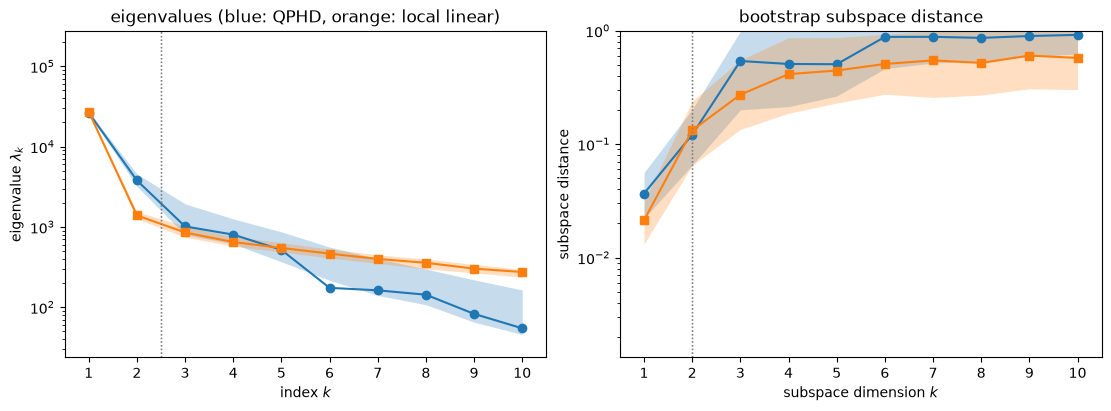

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
ac.plotting.plot_eigenvalues(subq, ax=axs[0], k_max=10)
ac.plotting.plot_eigenvalues(sub, ax=axs[0], k_max=10, line_kw={"color": "C1", "marker": "s"},
                             band_kw={"color": "C1"})
axs[0].set_title("eigenvalues (blue: QPHD, orange: local linear)")
ac.plotting.plot_subspace_errors(subq, ax=axs[1], k_max=10)
ac.plotting.plot_subspace_errors(sub, ax=axs[1], k_max=10, line_kw={"color": "C1", "marker": "s"},
                                 band_kw={"color": "C1"})
axs[1].set_title("bootstrap subspace distance")
plt.close(fig)
fig

QPHD has two gaps: $\lambda_1/\lambda_2 = 6.97$ and $\lambda_2/\lambda_3 = 3.74$, then 1.27 and 1.55. Its
first direction has a mean bootstrap distance of 0.037 and its two-dimensional subspace 0.121, while the
three-dimensional subspace jumps to 0.541. The first direction leaves 0.205 of the trace and the first two leave
0.091. The local linear spectrum has a single, larger gap, $\lambda_1/\lambda_2 = 19.57$ (then 1.63, 1.32,
1.18). That larger gap comes from the estimator. The 25-run neighbourhoods have a median radius of 2.30 in
normalized units, more than the side 2 of the cube, so each "local" fit spans much of the design. The mean
local gradient is within 0.044 (relative) of the slope of a single global linear fit. Gradients that are
close to one global slope give a $\mathbf{C}$ concentrated on one direction, which inflates
$\lambda_1/\lambda_2$ and hides curvature along the second direction. With 15 inputs a linear fit needs at
least 16 runs, so a smaller neighbourhood is not an option for 491 runs. The QPHD spectrum is the one used
below.

### Eigenvectors

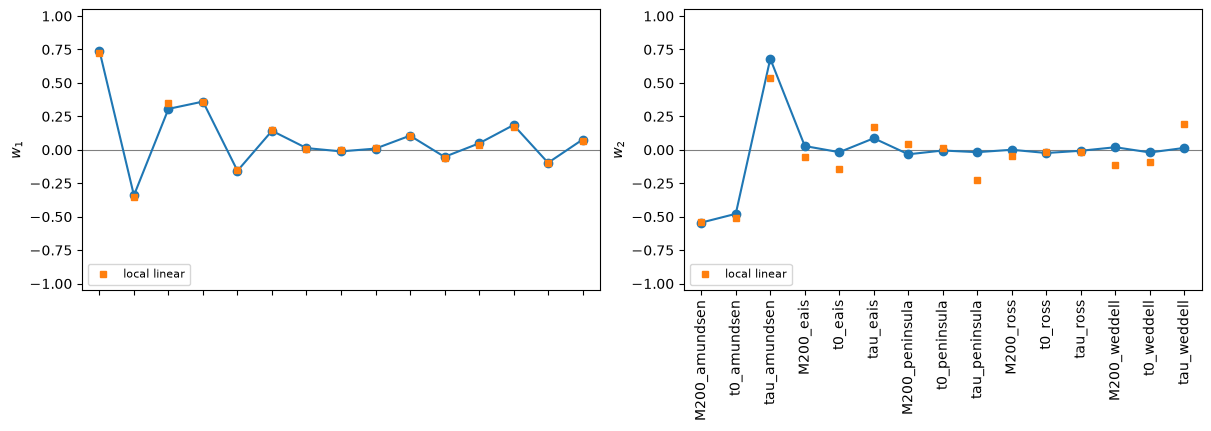

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
ac.plotting.plot_eigenvectors(subq, indices=[0, 1], labels=names, ax=axs)
for ax, j in zip(axs, (0, 1)):
    ax.plot(np.arange(1, 16), sub.W[:, j], "s", color="C1", ms=5, label="local linear")
    ax.legend(loc="lower left", fontsize=8)
plt.close(fig)
fig

In [7]:
for j in (0, 1):
    w, wl = subq.W[:, j], sub.W[:, j]
    top = np.argsort(-np.abs(w))[:5]
    print(f"w{j + 1} (QPHD), largest weights: " + ", ".join(f"{names[i]} {w[i]:+.2f}" for i in top))
    print(f"   |cos| with the local linear w{j + 1}: {abs(w @ wl):.3f}")
for j in (0, 1):
    grp = {b: np.sum(subq.W[3 * k:3 * k + 3, j] ** 2) for k, b in enumerate(basins)}
    print(f"share of |w{j + 1}|^2 by basin: " + ", ".join(f"{b} {v:.4f}" for b, v in grp.items()))

w1 (QPHD), largest weights: M200_amundsen +0.74, M200_eais +0.36, t0_amundsen -0.34, tau_amundsen +0.31, M200_weddell +0.19
   |cos| with the local linear w1: 0.999
w2 (QPHD), largest weights: tau_amundsen +0.68, M200_amundsen -0.54, t0_amundsen -0.48, tau_eais +0.09, M200_peninsula -0.03
   |cos| with the local linear w2: 0.923
share of |w1|^2 by basin: amundsen 0.7591, eais 0.1747, peninsula 0.0004, ross 0.0163, weddell 0.0495
share of |w2|^2 by basin: amundsen 0.9884, eais 0.0086, peninsula 0.0015, ross 0.0006, weddell 0.0010


The first QPHD direction is dominated by the Amundsen basin: $M_{200}$ (+0.74), the inflection time $t_0$
(−0.34, an earlier rise means more melt) and the time scale $\tau$ (+0.31), which together hold 0.759 of
$\|\mathbf{w}_1\|^2$. The East Antarctic melt rate is next (+0.36; East Antarctica holds 0.175), then the
Weddell melt rate (+0.19). Weddell holds 0.050 of $\|\mathbf{w}_1\|^2$, Ross 0.016 and the Peninsula less
than 0.001. The second direction is almost entirely Amundsen (0.988 of $\|\mathbf{w}_2\|^2$): $\tau$ +0.68
against $M_{200}$ −0.54 and $t_0$ −0.48, a contrast between the shape of the Amundsen sigmoid and its size.
The QPHD and local linear first directions agree closely ($|\cos| = 0.999$); on the second they agree less
($|\cos| = 0.923$).

### Sufficient summary plots

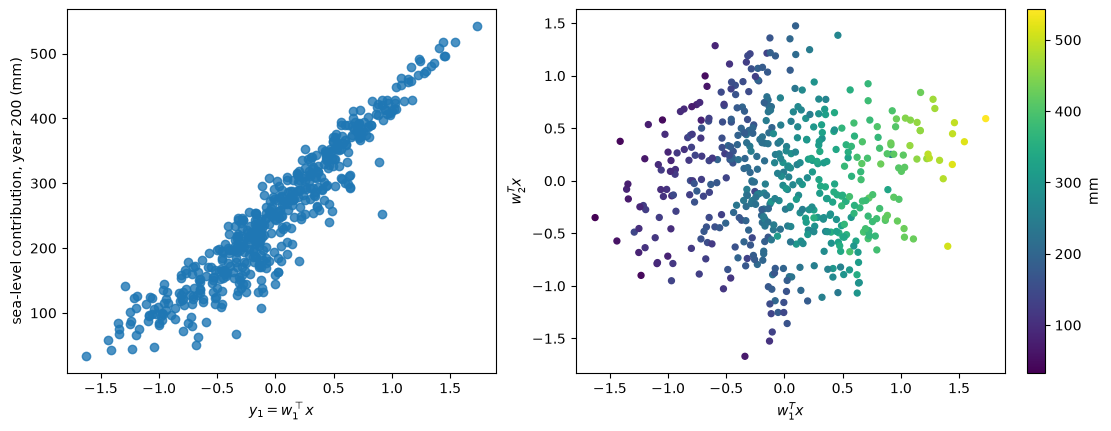

In [8]:
y = space.to_normalized(X) @ subq.W[:, :2]
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
ac.plotting.plot_sufficient_summary(ac.with_dimension(subq, 1), X=X, f=f, ax=axs[0],
                                    qoi_label="sea-level contribution, year 200 (mm)")
sc = axs[1].scatter(y[:, 0], y[:, 1], c=f, s=18, cmap="viridis")
axs[1].set_xlabel(r"$w_1^T x$")
axs[1].set_ylabel(r"$w_2^T x$")
fig.colorbar(sc, ax=axs[1], label="mm")
plt.close(fig)
fig

In [9]:
s1 = ac.fit_surrogate(X=X, f=f, subspace=ac.with_dimension(subq, 1), kind="poly", degree=2)
s2 = ac.fit_surrogate(X=X, f=f, subspace=subq, kind="poly", degree=2)
s1l = ac.fit_surrogate(X=X, f=f, subspace=ac.with_dimension(sub, 1), kind="poly", degree=2)
s2l = ac.fit_surrogate(X=X, f=f, subspace=sub, kind="poly", degree=2)
sfull = ac.fit_surrogate(X=X, f=f, space=space, subspace=None, kind="poly", degree=2)
slin = ac.fit_surrogate(X=X, f=f, space=space, subspace=None, kind="poly", degree=1)
for lab, s in (("quadratic in w1 (QPHD)", s1), ("quadratic in w1, w2 (QPHD)", s2),
               ("quadratic in w1 (local linear)", s1l), ("quadratic in w1, w2 (local linear)", s2l),
               ("linear in all 15 inputs", slin), ("quadratic in all 15 inputs", sfull)):
    loo_pred = f - s.loo_residuals
    print(f"{lab:36s} LOO R^2 {s.loo_r_squared:.4f}   LOO correlation {np.corrcoef(loo_pred, f)[0, 1]:.4f}")

quadratic in w1 (QPHD)               LOO R^2 0.9000   LOO correlation 0.9487
quadratic in w1, w2 (QPHD)           LOO R^2 0.9510   LOO correlation 0.9752
quadratic in w1 (local linear)       LOO R^2 0.9000   LOO correlation 0.9487
quadratic in w1, w2 (local linear)   LOO R^2 0.9426   LOO correlation 0.9709
linear in all 15 inputs              LOO R^2 0.8844   LOO correlation 0.9404
quadratic in all 15 inputs           LOO R^2 0.9723   LOO correlation 0.9861


The sea-level contribution at year 200 rises smoothly and nearly linearly along $\mathbf{w}_1^\top\mathbf{x}$,
with a scatter around the trend that the other directions carry. In the right panel the colour changes mostly
along $w_1^\top x$, with a weaker change along $w_2^\top x$. The LOO $R^2$ values of the
surrogates on active variables are leave-one-out given $\mathbf{W}$ estimated from all 491 runs, so they are
slightly optimistic. A quadratic in $w_1^\top x$ has a LOO $R^2$ of 0.900. Adding $w_2^\top x$ raises it to
0.951 (0.943 with the local linear pair). A full quadratic in all 15 inputs reaches 0.972 and a linear fit in all
15 reaches 0.884.

**Dimension.** This notebook takes $n = 2$, which the evidence supports better than $n = 1$. The QPHD spectrum
has a second gap of 3.74 after the first of 6.97, and the next ratio is 1.27. The two-dimensional subspace is
well determined (bootstrap distance 0.121, against 0.541 in three dimensions). The left-out share of the trace
drops from 0.205 to 0.091. The second variable raises the LOO $R^2$ from 0.900 to 0.951, close to the 0.972 of the
full 15-input quadratic. The single large local linear gap (19.57) would have suggested
$n = 1$, but it comes from the non-local fits described above. $n = 1$ remains a usable one-variable
summary (LOO $R^2$ 0.900), because the first direction is the same in both estimates.

### Check: the design density

The estimates average over the stored, cross-correlated design. As a check, the full quadratic fit (LOO
$R^2$ above) is differentiated at 20 000 independent uniform points, the input distribution the paper
states, and at the 491 stored points; both matrices are compared with the QPHD estimate.

In [10]:
Xu = space.sample(20000, rng=SEED)
res = {}
for lab, P in (("491 stored points", X), ("20000 uniform points", Xu)):
    Gs = ac.predict_gradient(sfull, P)
    s = ac.active_subspace(grads=Gs, space=space, n=2)
    s = ac.orient(s, by="reference", reference=subq.W[:, :2], columns=2)
    e = s.eigenvalues
    res[lab] = s
    print(f"quadratic fit at {lab:20s}: lambda1/lambda2 {e[0] / e[1]:6.2f}, lambda2/lambda3 {e[1] / e[2]:5.2f},",
          f"1 - |cos(w1, QPHD w1)| {1 - abs(s.W[:, 0] @ subq.W[:, 0]):.1e}")
a, b = res["491 stored points"].W[:, :2], res["20000 uniform points"].W[:, :2]
print(f"1 - |cos| between the two quadratic-fit w1: {1 - abs(a[:, 0] @ b[:, 0]):.1e}; largest weight change {np.max(np.abs(a[:, 0] - b[:, 0])):.1e}")
print(f"distance between the two 2-D subspaces: {np.linalg.norm(a @ a.T - b @ b.T, 2):.1e}")

quadratic fit at 491 stored points   : lambda1/lambda2   6.99, lambda2/lambda3  3.62, 1 - |cos(w1, QPHD w1)| 1.5e-06


quadratic fit at 20000 uniform points: lambda1/lambda2   6.92, lambda2/lambda3  3.74, 1 - |cos(w1, QPHD w1)| 7.7e-06
1 - |cos| between the two quadratic-fit w1: 5.7e-06; largest weight change 1.9e-03
distance between the two 2-D subspaces: 6.8e-02


Under independent uniform inputs the first direction of the quadratic fit is practically the one it gives on
the stored points ($1-|\cos|$ of order 1e-6, largest weight change of order 1e-3). The two-dimensional
subspaces are 6.8e-02 apart. Both first directions agree with the QPHD $\mathbf{w}_1$ to $1-|\cos|$ of
order 1e-6. The gaps, $\lambda_1/\lambda_2$ = 6.99 at the stored
points and 6.92 under uniform inputs ($\lambda_2/\lambda_3$ = 3.62 and 3.74), match the QPHD values. The
correlation of the stored design therefore changes neither the active subspace nor its two gaps.

### Check: where the failed runs sit on the active variables

The 9 failed runs have no year-200 value, but their inputs place them on the year-200 active variables. The
cell gives, for each, the fraction of the 500 stored runs with a smaller $\mathbf{w}_1^\top\mathbf{x}$
(QPHD $\mathbf{w}_1$), and the failure rate among the runs in the top 10 % of $\mathbf{w}_1^\top\mathbf{x}$
against the rest.

In [11]:
ya = space.to_normalized(Xall) @ subq.W[:, :2]
pw = [(ya[:, 0] < v).mean() for v in ya[~ok, 0]]
pw2 = [(ya[:, 1] < v).mean() for v in ya[~ok, 1]]
top10 = ya[:, 0] >= np.quantile(ya[:, 0], 0.9)
print("failed runs, fraction of the 500 runs below on w1:", np.round(pw, 2).tolist(), f"(median {np.median(pw):.2f})")
print("                                       ... on w2:", np.round(pw2, 2).tolist(), f"(median {np.median(pw2):.2f})")
print(f"failure rate in the top 10 % of w1^T x: {int((~ok & top10).sum())} of {int(top10.sum())}",
      f"({(~ok & top10).sum() / top10.sum():.1%}); in the rest: {int((~ok & ~top10).sum())} of {int((~top10).sum())}",
      f"({(~ok & ~top10).sum() / (~top10).sum():.1%})")

failed runs, fraction of the 500 runs below on w1: [0.17, 0.62, 0.72, 0.55, 0.84, 0.92, 0.59, 0.76, 0.66] (median 0.66)
                                       ... on w2: [0.19, 0.74, 0.48, 0.44, 0.47, 0.59, 0.68, 0.76, 0.4] (median 0.48)
failure rate in the top 10 % of w1^T x: 1 of 50 (2.0%); in the rest: 8 of 450 (1.8%)


On the year-200 direction the failed runs are not concentrated in the upper tail. Their fractions of
runs below range from 0.17 to 0.92 (median 0.66), and on $\mathbf{w}_2$ they are spread around the middle
(median 0.48). Only 1 of the 50 runs in the top 10 % of $\mathbf{w}_1^\top\mathbf{x}$ failed (2.0 %), against 1.8 % of the
rest. Their year-100 contributions are high, but on the year-200 active variables they lie across the middle
and upper half. Dropping them loses little, and the loss is not concentrated in the tail.

### Year 100

The same estimate for the contribution at year 100 (the paper's other output, Figs. 8, 9).

In [12]:
sub100 = ac.active_subspace(X=X, f=f100, space=space, estimator="qphd", nboot=500, bootstrap_vectors=2, rng=SEED)
sub100 = ac.with_dimension(sub100, 2)
sub100 = ac.orient(sub100, by="covariance", X=X, f=f100, columns=2)
e = sub100.eigenvalues
s100 = ac.fit_surrogate(X=X, f=f100, subspace=ac.with_dimension(sub100, 1), kind="poly", degree=2)
s100b = ac.fit_surrogate(X=X, f=f100, subspace=sub100, kind="poly", degree=2)
s100f = ac.fit_surrogate(X=X, f=f100, space=space, subspace=None, kind="poly", degree=2)
w = sub100.W[:, 0]
top = np.argsort(-np.abs(w))[:5]
print(f"year 100 (QPHD): ratios lambda_k/lambda_k+1, k=1..3: {np.round(e[:3] / e[1:4], 2)};",
      f"subspace distance k=1, 2: {np.round(sub100.bootstrap_distances.mean(0)[:2], 3)}")
print("  w1 largest weights: " + ", ".join(f"{names[i]} {w[i]:+.2f}" for i in top))
print(f"  |cos| with the year-200 w1: {abs(w @ subq.W[:, 0]):.3f}")
print(f"  LOO R^2 of a quadratic in w1: {s100.loo_r_squared:.4f}; in w1, w2: {s100b.loo_r_squared:.4f};",
      f"in all 15 inputs: {s100f.loo_r_squared:.4f}")

year 100 (QPHD): ratios lambda_k/lambda_k+1, k=1..3: [11.77  1.24  1.12]; subspace distance k=1, 2: [0.053 0.527]
  w1 largest weights: M200_amundsen +0.54, tau_amundsen +0.54, t0_amundsen -0.40, tau_eais +0.30, M200_eais +0.25
  |cos| with the year-200 w1: 0.927
  LOO R^2 of a quadratic in w1: 0.8783; in w1, w2: 0.9069; in all 15 inputs: 0.9564


At year 100 QPHD gives one clear gap, 11.77, followed by 1.24 and 1.12. The subspace distance is 0.053
in one dimension and 0.527 in two, so here $n = 1$. The Amundsen inputs lead: $M_{200}$ +0.54, $\tau$ +0.54,
$t_0$ −0.40, then the East Antarctic $\tau$ (+0.30) and $M_{200}$ (+0.25). For $t_0 > 100$ yr a longer $\tau$
spreads the sigmoid and raises the anomaly earlier in the run, which matters more at year 100 than at year
200. The cosine with the year-200 $\mathbf{w}_1$ is 0.927. A quadratic in the one variable has a LOO $R^2$
of 0.878 (0.907 in two, 0.956 for the full quadratic).

## Comparison with the paper

The paper builds a Gaussian-process emulator, not an active subspace; the table compares what both report.

| quantity | paper (page) | this notebook |
|---|---|---|
| ensemble members | 500 (p. 2689, "the full 500-member CISM ensemble") | 500 stored, 491 reach year 200 (9 flagged) |
| contribution at year 100 | 0.5–96 mm (p. 2691) | 0.50–95.81 mm (491 runs; the failed runs fall inside) |
| contribution at year 200 | 33–543 mm (p. 2691) | 33.03–542.77 mm (491 runs) |
| emulator validation, correlation at year 100 / 200 | 0.98 / 0.99, 20 % hold-out (Fig. 8, p. 2690) | year 200, LOO given $\mathbf{W}$: 0.9487 (quadratic in $w_1$), 0.9752 (in $w_1, w_2$), 0.9861 (full quadratic); a different validation and surrogate |
| active subspace, eigenvalues, directions | not reported | QPHD $\lambda_1/\lambda_2$ = 6.97, $\lambda_2/\lambda_3$ = 3.74, $n = 2$; $\mathbf{w}_1$ led by Amundsen $M_{200}$, $\mathbf{w}_2$ an Amundsen $\tau$ vs. $M_{200}$, $t_0$ contrast (local linear $\lambda_1/\lambda_2$ = 19.57, inflated by non-local fits) |
| input dependence | "a random basal melt rate curve generated with the Sobol' sequence is chosen for each basin. We have chosen not to assume any correlation between basins." (p. 2689) | stored design: $\tau$ Peninsula–Weddell r = +0.63 |

The year-100 and year-200 ranges printed above round to the paper's values, which supports that the stored
runs are those of the paper; the paper does not mention the 9 failed runs, and its R scripts drop them.

## References

* M. Berdahl, G. Leguy, W. H. Lipscomb, N. M. Urban, Statistical emulation of a perturbed basal melt
  ensemble of an ice sheet model to better quantify Antarctic sea level rise uncertainties, *The Cryosphere*
  15(6), 2683–2699 (2021), [doi:10.5194/tc-15-2683-2021](https://doi.org/10.5194/tc-15-2683-2021).
* M. Berdahl, mberdahl-uw/TheCryosphere-CISM_emulator: CISM Emulator Code and data (Version 1.0.0), Zenodo
  (2021), [doi:10.5281/zenodo.4902149](https://doi.org/10.5281/zenodo.4902149); repository
  https://github.com/mberdahl-uw/EmulatorPaper.
* W. H. Lipscomb, S. F. Price, M. J. Hoffman, G. R. Leguy, A. R. Bennett, S. L. Bradley, K. J. Evans,
  J. G. Fyke, J. H. Kennedy, M. Perego, D. M. Ranken, W. J. Sacks, A. G. Salinger, L. J. Vargo, P. H. Worley,
  Description and evaluation of the Community Ice Sheet Model (CISM) v2.1, *Geoscientific Model Development*
  12(1), 387–424 (2019), [doi:10.5194/gmd-12-387-2019](https://doi.org/10.5194/gmd-12-387-2019).
* A. Levermann, R. Winkelmann, T. Albrecht, et al., Projecting Antarctica's contribution to future sea level
  rise from basal ice shelf melt using linear response functions of 16 ice sheet models (LARMIP-2),
  *Earth System Dynamics* 11(1), 35–76 (2020), [doi:10.5194/esd-11-35-2020](https://doi.org/10.5194/esd-11-35-2020).
* P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM
  (2015), [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## Acknowledgments

The paper's work was supported by the US DOE Office of Science (grant LANL21035007; Biological and
Environmental Research Early Career Research Program), Empire State Development Corporation (award AA289),
and the National Center for Atmospheric Research, sponsored by the US National Science Foundation
(cooperative agreement 1852977); computing used the Los Alamos National Laboratory Institutional Computing
Program and the NCAR Cheyenne supercomputer (p. 2696).